# MLOps HW1 Part B - Divvy bike share x Chicago weather
Descriptive analytics only (no prediction).

**Sources**
* Divvy trip data, 25 monthly files (Sep 2024 - Sep 2026), ~12.4M trips
* NOAA GHCN-Daily, Chicago Midway Airport (`USW00014819`)

**Pipeline** (`partb_pipeline.py`; every step emits OpenLineage events to
`lineage_events.jsonl` for the lineage diagram in Marquez):

`divvy zips -> clean_trips -> aggregate_trips -> join_weather <- clean_weather <- Midway CSV`
`-> build_report (this notebook) -> figures/`

In [1]:
import os
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from lineage import lineage_run

WORK, FIG = "work", "figures"
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid")

# Run the ETL once if its outputs are missing (~5 min on a laptop)
if not os.path.exists(f"{WORK}/daily_rides_weather.parquet"):
    subprocess.run(["python", "partb_pipeline.py"], check=True)

daily = pd.read_parquet(f"{WORK}/daily_rides_weather.parquet")
rides = pd.read_parquet(f"{WORK}/daily_rides.parquet")
hourly = pd.read_parquet(f"{WORK}/hourly_rides.parquet")
stations = pd.read_parquet(f"{WORK}/station_rides.parquet")
quality = pd.read_parquet(f"{WORK}/trip_quality.parquet")
print(f"{daily.total_rides.sum():,.0f} clean rides over {len(daily)} days")

12,204,601 clean rides over 760 days


## 1. Data quality and transformations
What the cleaning step removed or flagged, per monthly file.

In [2]:
q = quality.copy()
totals = q[["rows_raw", "duplicates", "too_short", "too_long_or_negative",
            "missing_start_station", "rows_clean"]].sum()
print(totals.to_string())
print(f"\ndropped: {1 - totals.rows_clean / totals.rows_raw:.1%} of raw rows"
      f" | rides with no start station: "
      f"{totals.missing_start_station / totals.rows_clean:.1%}")
mislabeled = q[q.inner_file.str[:6] != q.month]
mislabeled[["month", "inner_file", "label_matches_data"]]

rows_raw                 12532582
duplicates                      0
too_short                  315954
too_long_or_negative        11640
missing_start_station     2427228
rows_clean               12204988

dropped: 2.6% of raw rows | rides with no start station: 19.9%


,month,inner_file,label_matches_data
16,202601,202501-divvy-tripdata.csv,True


* About 2.6% of raw rows were dropped. Almost all of them are rides
under 1 minute (false starts or re-docks); a few are over 24 hours or have
negative durations. There were no duplicate `ride_id`s.
* About 20% of rides have **no start station**. These are mostly dockless
e-bike trips, so they are kept for counts but not for station rankings.
* **Mislabeled source file:** Divvy's `202601` zip contains a CSV named
`202501-divvy-tripdata.csv`. Unzipping everything into one folder would
silently overwrite January 2025 with January 2026. The pipeline reads each
zip directly and checks that the month label matches the data
(`label_matches_data = True`). This is exactly what lineage helps you
catch.
* Weather: Midway does not report `TAVG` or `SNOW` in this window. `TAVG` is
filled from (TMAX+TMIN)/2, and snow is measured as *snow on the ground*
(`SNWD > 0`). Units are converted from tenths of °C, tenths of mm, and
tenths of m/s to °F, inches, and mph.

## 2. EDA of the reporting table

In [3]:
daily[["total_rides", "member_rides", "casual_rides", "avg_min",
       "tavg_f", "precip_in", "wind_mph", "snow_depth_in"]].describe().round(1)

,total_rides,member_rides,casual_rides,avg_min,tavg_f,precip_in,wind_mph,snow_depth_in
count,760.0,760.0,760.0,760.0,760.0,760.0,760.0,286.0
mean,16058.7,10318.8,5739.9,13.6,54.7,0.1,9.9,0.4
std,9009.2,5044.2,4520.6,2.8,20.0,0.3,3.5,1.1
min,429.0,364.0,65.0,8.2,-1.8,0.0,3.1,0.0
25%,7938.8,6064.0,1571.2,11.4,40.6,0.0,7.2,0.0
50%,16134.0,10837.0,4935.0,13.3,57.5,0.0,9.4,0.0
75%,23808.2,14408.5,8762.5,15.2,71.5,0.0,12.3,0.0
max,39338.0,20272.0,21079.0,27.0,87.1,3.3,25.3,7.0


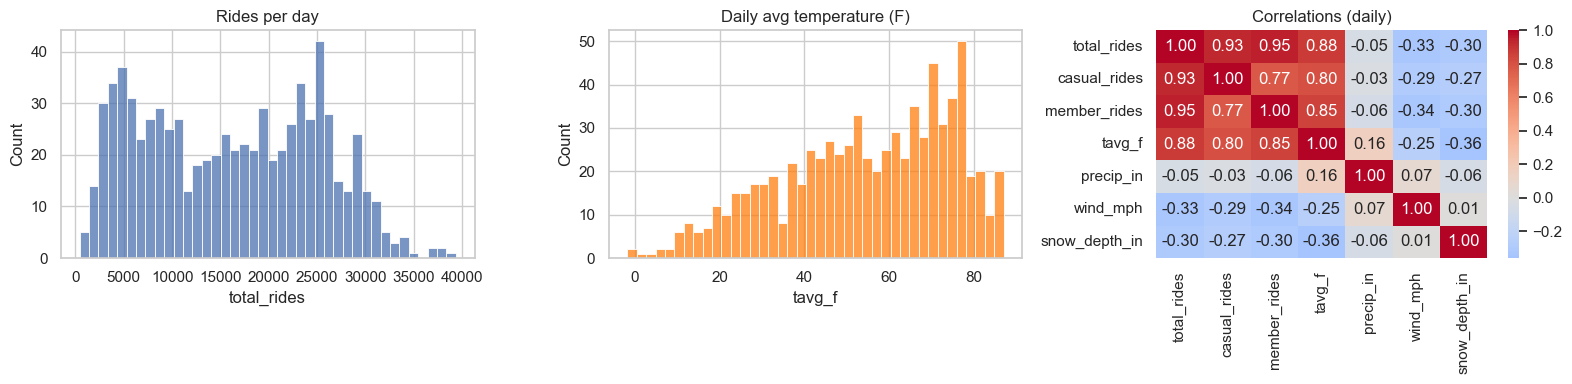

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(daily.total_rides, bins=40, ax=ax[0])
ax[0].set_title("Rides per day")
sns.histplot(daily.tavg_f, bins=40, ax=ax[1], color="tab:orange")
ax[1].set_title("Daily avg temperature (F)")
corr = daily[["total_rides", "casual_rides", "member_rides", "tavg_f",
              "precip_in", "wind_mph", "snow_depth_in"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            ax=ax[2])
ax[2].set_title("Correlations (daily)")
plt.tight_layout()
plt.show()

## 3. Insight - ridership is growing and very seasonal

Oct24-Sep25: 5,397,582  Oct25-Sep26: 6,007,182  growth: +11.3%
peak month 2026-08 = 846,510, low month 2026-01 = 133,743


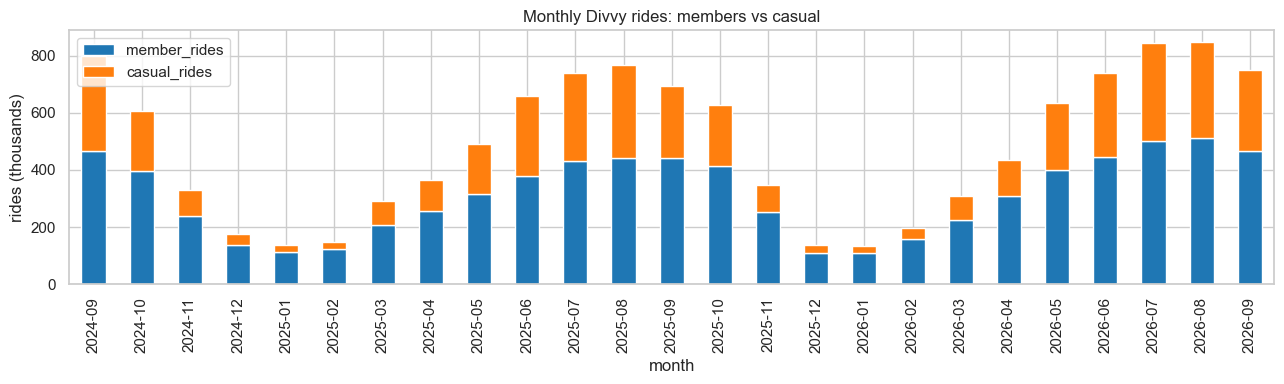

In [6]:
m = daily.groupby("month")[["member_rides", "casual_rides"]].sum()
y1 = daily[daily.date.between("2024-10-01", "2025-09-30")].total_rides.sum()
y2 = daily[daily.date.between("2025-10-01", "2026-09-30")].total_rides.sum()
print(f"Oct24-Sep25: {y1:,.0f}  Oct25-Sep26: {y2:,.0f}  "
      f"growth: {y2 / y1 - 1:+.1%}")
print(f"peak month {m.sum(1).idxmax()} = {m.sum(1).max():,.0f}, "
      f"low month {m.sum(1).idxmin()} = {m.sum(1).min():,.0f}")
ax = (m / 1000).plot.bar(stacked=True, figsize=(13, 4),
                         color=["tab:blue", "tab:orange"])
ax.set_ylabel("rides (thousands)")
ax.set_title("Monthly Divvy rides: members vs casual")
plt.tight_layout()
plt.savefig(f"{FIG}/1_monthly_rides.png", dpi=150)
plt.show()

## 4. Insight - temperature drives ridership, especially casual riders

           member_rides  casual_rides
temp_band                            
<32F             3381.0         723.0
32-50F           6997.0        2361.0
50-65F          11141.0        5673.0
65-80F          14812.0        9867.0
80F+            14626.0       10257.0
warmest / coldest band ratio: {'member_rides': 4.3, 'casual_rides': 14.2}


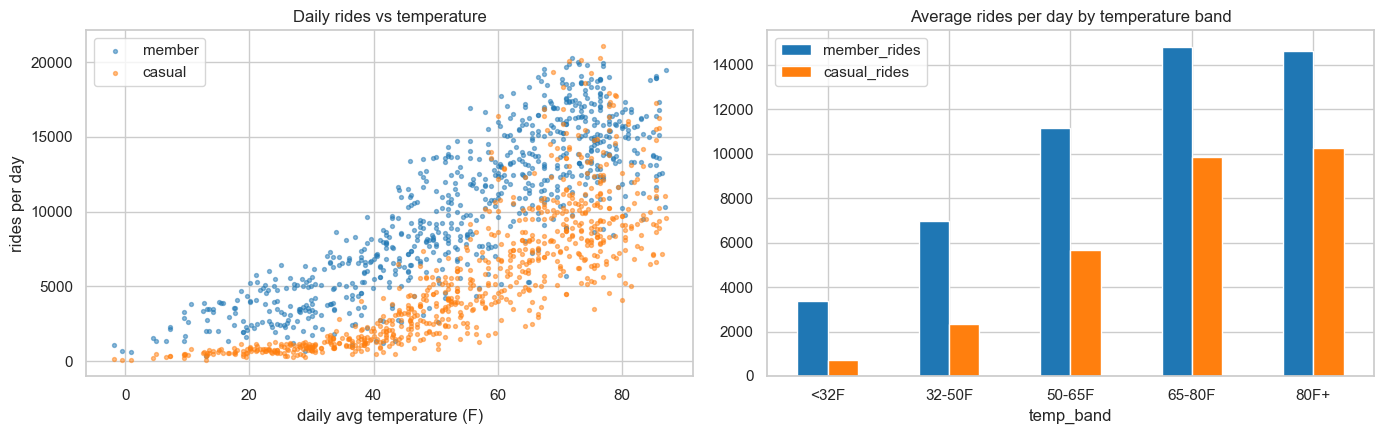

In [7]:
order = ["<32F", "32-50F", "50-65F", "65-80F", "80F+"]
band = daily.groupby("temp_band")[["member_rides",
                                   "casual_rides"]].mean().loc[order]
print(band.round(0))
print("warmest / coldest band ratio:",
      (band.loc["80F+"] / band.loc["<32F"]).round(1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for col, c in [("member_rides", "tab:blue"), ("casual_rides", "tab:orange")]:
    ax[0].scatter(daily.tavg_f, daily[col], s=8, alpha=.5, color=c,
                  label=col.split("_")[0])
ax[0].set_xlabel("daily avg temperature (F)")
ax[0].set_ylabel("rides per day")
ax[0].legend()
ax[0].set_title("Daily rides vs temperature")
band.plot.bar(ax=ax[1], color=["tab:blue", "tab:orange"], rot=0)
ax[1].set_title("Average rides per day by temperature band")
plt.tight_layout()
plt.savefig(f"{FIG}/2_temperature.png", dpi=150)
plt.show()

## 5. Insight - rain cuts rides at every temperature

            dry day  rain day (>=0.1 in)  drop
temp_band                                     
<32F        4184.13              2199.20  0.47
32-50F      9765.56              7022.77  0.28
50-65F     18189.30             11354.85  0.38
65-80F     26109.32             19927.04  0.24
80F+       25752.70             21405.70  0.17

snow on ground vs not (days < 40F): 3,955 vs 5,496 rides/day (-28%)


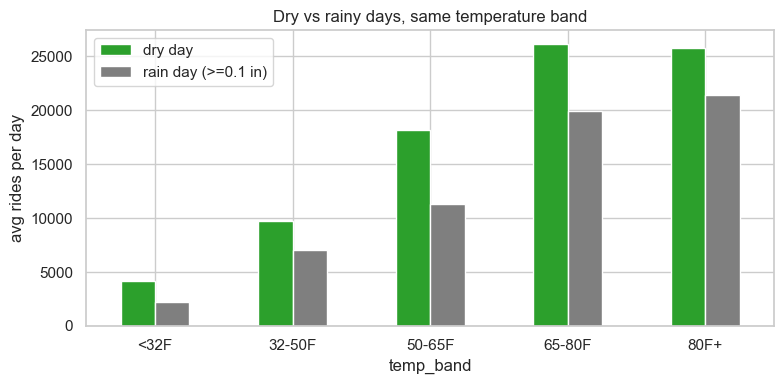

In [8]:
rain = daily.pivot_table(index="temp_band", columns="rain_day",
                         values="total_rides", aggfunc="mean").loc[order]
rain.columns = ["dry day", "rain day (>=0.1 in)"]
rain["drop"] = 1 - rain.iloc[:, 1] / rain.iloc[:, 0]
print(rain.round(2))
cold = daily[daily.tavg_f < 40].groupby("snow_on_ground").total_rides.mean()
print(f"\nsnow on ground vs not (days < 40F): {cold[1]:,.0f} vs {cold[0]:,.0f}"
      f" rides/day ({cold[1] / cold[0] - 1:+.0%})")
ax = rain.iloc[:, :2].plot.bar(figsize=(8, 4), rot=0,
                               color=["tab:green", "tab:gray"])
ax.set_ylabel("avg rides per day")
ax.set_title("Dry vs rainy days, same temperature band")
plt.tight_layout()
plt.savefig(f"{FIG}/3_rain.png", dpi=150)
plt.show()

## 6. Insight - members commute, casual riders ride on weekends

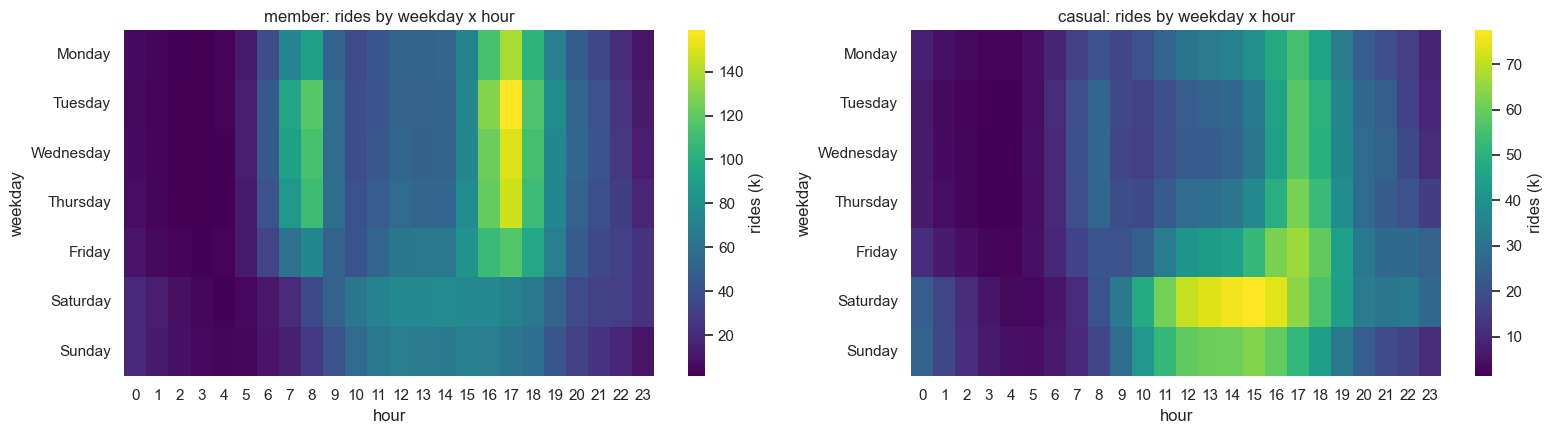

weekend vs weekday avg rides/day: {'member_rides': '-23%', 'casual_rides': '+48%'}
avg ride length (min): {'casual': 19.1, 'member': 12.1}


In [9]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday",
        "Saturday", "Sunday"]
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for i, who in enumerate(["member", "casual"]):
    grid = hourly[hourly.member_casual == who].pivot(
        index="weekday", columns="hour", values="rides").loc[days]
    sns.heatmap(grid / 1000, cmap="viridis", ax=ax[i],
                cbar_kws={"label": "rides (k)"})
    ax[i].set_title(f"{who}: rides by weekday x hour")
plt.tight_layout()
plt.savefig(f"{FIG}/4_weekday_hour.png", dpi=150)
plt.show()
wk = daily.groupby("is_weekend")[["member_rides", "casual_rides"]].mean()
print("weekend vs weekday avg rides/day:",
      (wk.loc[1] / wk.loc[0] - 1).map("{:+.0%}".format).to_dict())
dur = rides.groupby("member_casual")[["total_min", "rides"]].sum()
print("avg ride length (min):",
      (dur.total_min / dur.rides).round(1).to_dict())

## 7. Insight - e-bikes are taking over, and riders go to different places

rideable_type  classic_bike  electric_bike  electric_scooter
q                                                           
2024Q3                0.392          0.436             0.172
2024Q4                0.449          0.551             0.000
2025Q1                0.370          0.630             0.000
2025Q2                0.382          0.618             0.000
2025Q3                0.356          0.644             0.000
2025Q4                0.332          0.668             0.000
2026Q1                0.323          0.677             0.000
2026Q2                0.307          0.693             0.000
2026Q3                0.265          0.735             0.000


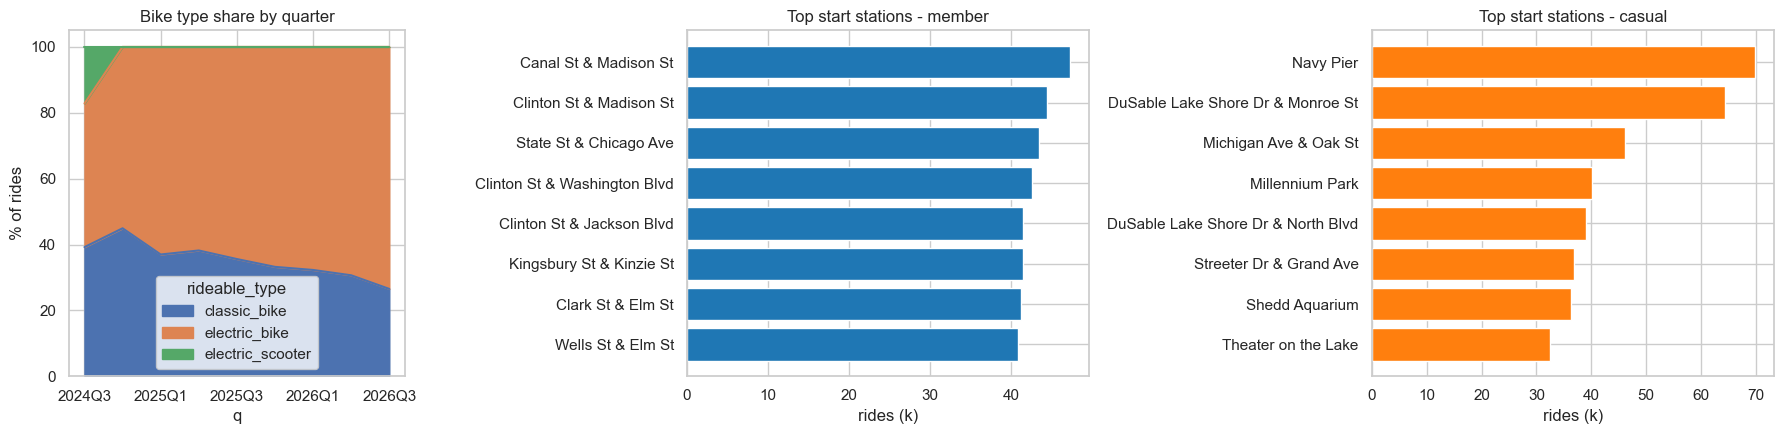

In [10]:
q_type = rides.assign(q=rides.date.dt.to_period("Q").astype(str)) \
    .pivot_table(index="q", columns="rideable_type", values="rides",
                 aggfunc="sum").fillna(0)
share = q_type.div(q_type.sum(1), axis=0)
print(share.round(3))
top = (stations.sort_values("rides", ascending=False)
       .groupby("member_casual").head(8))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5),
                       gridspec_kw={"width_ratios": [1, 1.2, 1.2]})
(share * 100).plot.area(ax=ax[0])
ax[0].set_ylabel("% of rides")
ax[0].set_title("Bike type share by quarter")
for i, who in enumerate(["member", "casual"], start=1):
    t = top[top.member_casual == who].sort_values("rides")
    ax[i].barh(t.start_station_name, t.rides / 1000,
               color="tab:blue" if who == "member" else "tab:orange")
    ax[i].set_title(f"Top start stations - {who}")
    ax[i].set_xlabel("rides (k)")
plt.tight_layout()
plt.savefig(f"{FIG}/5_bikes_stations.png", dpi=150)
plt.show()

## 8. Summary
1. **Growth:** about 6.0M rides in Oct 2025-Sep 2026, up about **11%** on
the year before. July and August 2026 are the busiest months on record in
this window (about 846k each). January is only about 16% of the peak.
2. **Temperature is the #1 driver** (daily correlation 0.88). Casual rides
are about **14x** higher on 80°F+ days than below freezing; member rides
are only about 4x higher. Members ride year-round, while casual demand is
fair-weather leisure.
3. **Rain** (≥ 0.1 in) cuts rides by about **17-48%** compared with dry days
in the same temperature band. On cold days (< 40°F), snow on the ground
means about 28% fewer rides.
4. **Two kinds of riders:** members show commute peaks at 8 am and 5 pm on
weekdays. Casual riders peak on weekend afternoons (+48% on weekends,
while members drop 23%). Casual rides are longer (about 19 vs 12 min).
5. **E-bikes:** share rose from about 55% (Q4 2024) to about 74%
(Q3 2026). Scooters show up only in Sep 2024. Casual riders start at the
lakefront and tourist spots (Navy Pier, DuSable Lake Shore Dr, Millennium
Park), while members start at commuter hubs near the Loop train stations
(Canal and Clinton St at Madison).

**Reporting use:** operations (rebalance e-bikes before warm weekends,
staff the lakefront stations) and marketing (convert warm-weather casual
riders into members).

## 9. Record the reporting step in the lineage graph

In [11]:
with lineage_run(
        "build_report",
        "Descriptive analytics notebook: monthly trend, temperature and "
        "rain effects, weekday x hour patterns, bike-type share, top "
        "stations.",
        ["partb/work/daily_rides_weather", "partb/work/daily_rides",
         "partb/work/hourly_rides", "partb/work/station_rides",
         "partb/work/trip_quality"],
        ["partb/figures (report charts)"]):
    pass
print(sorted(os.listdir(FIG)))

['1_monthly_rides.png', '2_temperature.png', '3_rain.png', '4_weekday_hour.png', '5_bikes_stations.png', 'lineage_preview.dot', 'lineage_preview.png']
